# 04 · Model 1: helmet color

We train a model that looks at a helmet and gives the probability of each of the 5 colors.

## Architecture
| # | Layer | Output | Weights | Trained? |
|---|---|---|---|---|
| 0 | Input: RGB photo 224 × 224, values 0–255 | 224 × 224 × 3 | 0 | – |
| 1 | ResNet50 preprocessing (fixed 1 × 1 convolution: RGB → BGR, subtract the ImageNet mean) | 224 × 224 × 3 | 12 | No |
| 2 | ResNet50 from ImageNet without its last layer (`include_top=False`) | 7 × 7 × 2,048 | 23,587,712 | No (frozen) |
| 3 | Global average pooling: the mean of each of the 2,048 channels | 2,048 | 0 | – |
| 4 | Dropout 0.3 (only during training) | 2,048 | 0 | – |
| 5 | Dense layer, 5 outputs, softmax | 5 | 10,240 weights + 5 biases | **Yes** |

- **Frozen** means the weights do not change. Only layer 5 learns.
- The output of layer 3 is the **feature vector**: 2,048 numbers that describe the image.
- **Softmax** turns the 5 outputs into probabilities that add up to 1.
- Training of layer 5: Adam optimizer (rate 1e-3), cross-entropy loss, 60 epochs, batch of 32, L2 penalty 1e-3, balanced class weights, seed 0.

Because ResNet50 is frozen, each image goes through it only once and we keep its vector. Layer 5 is then trained on those vectors. The result is the same as training the full model with ResNet50 frozen, but much faster.

## How we test it: leave one background out
We train with the images (originals and augmented copies) of 5 backgrounds and test **only on the original photos** of the background left out. We repeat this for each of the 6 backgrounds. The augmented copies of a test photo never enter the training of that round.

A random split would put almost identical burst photos in train and test, and the result would look higher than it is.

Input: `data/helmets_augmented/` from notebook 03. Output: `models/helmet_color_model.keras`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import keras
from keras import layers
from keras.applications.resnet50 import ResNet50, preprocess_input
from sklearn.metrics import confusion_matrix, balanced_accuracy_score, classification_report

SEED = 0
keras.utils.set_random_seed(SEED)
REPO = Path.cwd().parent
AUGMENTED = REPO / "data/helmets_augmented"
OUTPUTS, MODELS = REPO / "outputs", REPO / "models"
OUTPUTS.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
SIZE = 224
COLORS = ["green", "orange", "red", "transparent", "yellow"]

man = pd.read_csv(AUGMENTED / "manifest.csv")
assert len(man) == 1750 and (man.color.value_counts() == 350).all()
X = np.stack([np.asarray(Image.open(AUGMENTED / f).convert("RGB")) for f in man.file])
assert X.shape[1:] == (SIZE, SIZE, 3)
y = man.color.map({c: i for i, c in enumerate(COLORS)}).to_numpy()
background = man.background.to_numpy()
original = ~man.augmented.to_numpy()
backgrounds = sorted(set(background))
pd.crosstab(man.background, man.augmented, margins=True).rename(columns={False: "originals", True: "augmented"})

augmented,originals,augmented,All
background,,,
black,36,350,386
floor,33,314,347
green,7,42,49
grey,29,266,295
table,32,282,314
white,37,322,359
All,174,1576,1750


## 1. Layers 1–3: frozen ResNet50 → feature vector of 2,048

In [2]:
extractor = ResNet50(include_top=False, pooling="avg", weights="imagenet", input_shape=(SIZE, SIZE, 3))
extractor.trainable = False
# np.array makes a copy: preprocess_input writes over its input
F = extractor.predict(preprocess_input(np.array(X, dtype="float32")), batch_size=32, verbose=0)
print(F.shape, "| ResNet50 weights:", f"{extractor.count_params():,}")

(1750, 2048) | ResNet50 weights: 23,587,712


## 2. Layers 4–5: dropout + dense layer with 5 outputs

In [3]:
def train_head(Fe, ye):
    keras.utils.set_random_seed(SEED)
    head = keras.Sequential([keras.Input((2048,)), layers.Dropout(0.3),
                             layers.Dense(len(COLORS), activation="softmax", kernel_regularizer=keras.regularizers.l2(1e-3))],
                            name="color_head")
    head.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    n = np.bincount(ye, minlength=len(COLORS))
    hist = head.fit(Fe, ye, epochs=60, batch_size=32, verbose=0,
                    class_weight={i: len(ye) / (len(COLORS) * n[i]) for i in range(len(COLORS)) if n[i]})
    return head, hist.history

## 3. Leave-one-background-out test

In [4]:
prob = np.full((len(y), len(COLORS)), np.nan)
histories = {}
for b in backgrounds:
    train = background != b                     # originals + augmented copies of the other 5 backgrounds
    test = (background == b) & original         # only the real photos of the background left out
    head, histories[b] = train_head(F[train], y[train])
    prob[test] = head.predict(F[test], verbose=0)
    print(f"{b:6s} train {train.sum():4d} | test {test.sum():3d}")

yt, pred = y[original], prob[original].argmax(1)
res = pd.DataFrame({"background": background[original], "correct": pred == yt}).groupby("background").correct.agg(["size", "mean"])
res.loc["TOTAL"] = [len(yt), (pred == yt).mean()]
print("Balanced accuracy:", round(balanced_accuracy_score(yt, pred), 3),
      "| lowest probability of the chosen color:", round(prob[original].max(1).min(), 3))
res.round(3)

black  train 1364 | test  36


floor  train 1403 | test  33


green  train 1701 | test   7


grey   train 1455 | test  29


table  train 1436 | test  32


white  train 1391 | test  37
Balanced accuracy: 1.0 | lowest probability of the chosen color: 0.526


,size,mean
background,,
black,36.0,1.0
floor,33.0,1.0
green,7.0,1.0
grey,29.0,1.0
table,32.0,1.0
white,37.0,1.0
TOTAL,174.0,1.0


### Confusion matrix

Rows are the true color and columns the predicted color. Correct answers are on the diagonal.

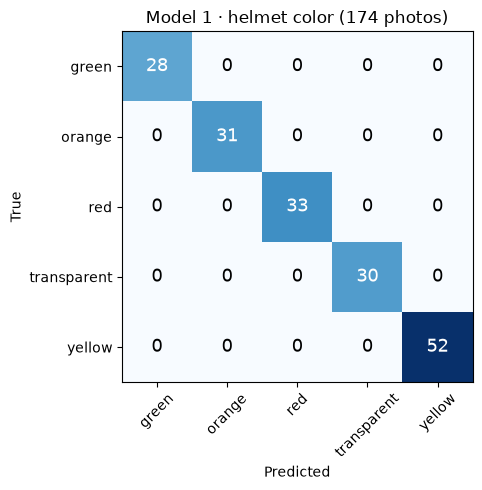

              precision    recall  f1-score   support

       green      1.000     1.000     1.000        28
      orange      1.000     1.000     1.000        31
         red      1.000     1.000     1.000        33
 transparent      1.000     1.000     1.000        30
      yellow      1.000     1.000     1.000        52

    accuracy                          1.000       174
   macro avg      1.000     1.000     1.000       174
weighted avg      1.000     1.000     1.000       174



In [5]:
cm = confusion_matrix(yt, pred, labels=range(len(COLORS)))
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", fontsize=13, color="white" if v > cm.max() / 2 else "black")
ax.set_xticks(range(5), COLORS, rotation=45); ax.set_yticks(range(5), COLORS)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Model 1 · helmet color (174 photos)")
plt.tight_layout(); plt.savefig(OUTPUTS / "04_confusion_matrix_model1.png", dpi=150); plt.show()
print(classification_report(yt, pred, target_names=COLORS, digits=3))

In [6]:
pd.DataFrame({"file": man.file[original], "original": man.original[original], "background": background[original],
              "true": np.array(COLORS)[yt], "predicted": np.array(COLORS)[pred],
              "prob": prob[original].max(1).round(3)}).to_csv(OUTPUTS / "04_predictions.csv", index=False)
print((pred != yt).sum(), "errors")

0 errors


## 4. Final model, trained on all 1,750 images

The test above estimates how well this model works. The final model uses all the images, so no background is left out.

We save ResNet50 and the new layer as one `.keras` file. The ResNet50 preprocessing is stored as a fixed 1 × 1 convolution, so the file loads without extra code.

In [7]:
head, _ = train_head(F, y)

preprocess = layers.Conv2D(3, 1, trainable=False, name="resnet_preprocess")
preprocess.build((None, SIZE, SIZE, 3))
preprocess.set_weights([np.eye(3, dtype="float32")[::-1].reshape(1, 1, 3, 3), -np.array([103.939, 116.779, 123.68], "float32")])
inp = keras.Input((SIZE, SIZE, 3), name="photo")
model = keras.Model(inp, head(extractor(preprocess(inp))), name="helmet_color_model")
assert np.allclose(model.predict(X[:8].astype("float32"), verbose=0), head.predict(F[:8], verbose=0), atol=1e-4)
model.summary()

model.save(MODELS / "helmet_color_model.keras")
(MODELS / "color_classes.json").write_text(json.dumps(COLORS))

Model: "helmet_color_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ photo (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocess (Conv2D)      │ (None, 224, 224, 3)    │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ color_head (Sequential)         │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,969 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,724 (89.98 MB)

## 5. Limits
- There is **one helmet per color**. More copies of the same photos do not prove that the model uses the color. Photos of other helmets are needed to test that.
- The photos have plain backgrounds and nobody wears the helmet. Notebook 10 applies this model to real work photos.